# 02. Run 간 / Run 내 변동과 불량 — 어떤 Run·어떤 순간이 불량과 관계있나

**출처**: 09/29 회의록 ① Run 단위 데이터 분석, ③ 불량 유형별 분석 결과 (CN7 초기 세팅·미성형은 구분 가능, CN7 가스·RG3 가스·RG3 미성형은 추가 분석 필요)

| 장 | 질문 | 방법 |
|---|---|---|
| 2 | 어떤 변수가 **Run 성격**(Run 간)이고 어떤 변수가 **샷 노이즈**(Run 내)인가? | Run 간 비중 η² = Run 평균 차이 분산 / 전체 분산 |
| 3 | **어떤 Run**이 불량과 관계있나? | Run 평균 프로파일 vs Run 불량률 |
| 4 | 같은 Run 안에서 **불량 샷만 튀는 변수**가 있나? | 같은 Run 양품 기준 robust z, Cliff's δ |
| 5 | 팀원이 본 **CN7 초기허용불량·미성형 특징**은 무엇이고 실제로 구분되나? | 유형별 z 프로파일, 타임라인 |
| 6 | 그 특징을 규칙으로 쓰면 **탐지·오탐**은? | 과도구간 규칙별 혼동표 |
| 7 | Run 수가 적은 문제를 어떻게 보완하나? | Run을 **30샷 시간 블록**으로 쪼개 블록 평균 vs 블록 불량률 |

**데이터**: `base/cn7_shots.csv`, `base/rg3_shots.csv` (split `제외` 빼고 2차 + 추가 전체). 판단은 2차 기준, 추가 기간은 함께 표시(팀 원칙)

**주의**: 불량 수가 매우 적고(CN7 초기허용불량 5샷 = 1회 이벤트, CN7 미성형 4샷 중 3샷이 연속) Run 수도 제품당 6개라 **통계 검정이 아니라 기술(記述)적 판단**이다.

## 1. 설정·데이터

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

BASE_DIR = './base'
OUT_DIR = './outputs/run'
os.makedirs(OUT_DIR, exist_ok=True)
PRODUCTS = ['cn7', 'rg3']
BLOCK = 30          # 시간 블록 크기(샷)
Z_EVENT = 5         # 과도구간 규칙: Run 내 robust |z| 기준

_av = {f.name for f in font_manager.fontManager.ttflist}
for _f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
    if _f in _av:
        mpl.rcParams['font.family'] = _f; break
mpl.rcParams.update({'axes.unicode_minus': False, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5df', 'grid.linewidth': 0.6,
                     'axes.edgecolor': '#b5b4ad', 'axes.labelcolor': '#52514e',
                     'xtick.color': '#6f6e69', 'ytick.color': '#6f6e69'})
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 220)

INK = '#2b2a27'
SPLIT_COL = {'2차': '#2a78d6', '추가': '#eb6834'}
REASON_COL = {'정상': '#c3c2b7', '가스': '#e34948', '미성형': '#4a3aa7', '가스+미성형': '#e87ba4', '초기허용불량': '#eda100'}
SEQ = LinearSegmentedColormap.from_list('seq', ['#fcfcfb', '#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])

D = {}
for p in PRODUCTS:
    df = pd.read_csv(os.path.join(BASE_DIR, f'{p}_shots.csv'), parse_dates=['TimeStamp'])
    D[p] = df[df['split'] != '제외'].sort_values('TimeStamp').reset_index(drop=True)
VARS = [c[:-4] for c in D['cn7'].columns if c.endswith('_raw')]
raw = lambda c: f'{c}_raw'
for p in PRODUCTS:
    print(f'[{p}]', D[p].groupby(['split', 'Reason']).size().unstack(fill_value=0).to_dict('index'))

[cn7] {'2차': {'가스': 11, '가스+미성형': 2, '미성형': 1, '정상': 592, '초기허용불량': 0}, '추가': {'가스': 0, '가스+미성형': 0, '미성형': 1, '정상': 1367, '초기허용불량': 5}}
[rg3] {'2차': {'가스': 17, '미성형': 8, '정상': 566}, '추가': {'가스': 5, '미성형': 2, '정상': 29}}


## 2. Run 간 비중 (η²) — 변수가 Run 성격인가, 샷 노이즈인가

- **η² 높음 (≥ 0.5)**: 변수 변동 대부분이 Run 평균 차이 → "Run 전체 특성" 비교(3장)에 쓸 변수
- **η² 낮음 (< 0.1)**: Run 평균은 비슷하고 샷마다 흔들림 → "Run 내 튐"(4장)에서 볼 변수
- 회의록 가설: *가스 불량은 Run 내부 일부 샷이 아니라 Run 전체 평균 특성이 달라졌을 가능성* → η² 높은 변수에서 불량 Run이 튀는지 3장에서 확인

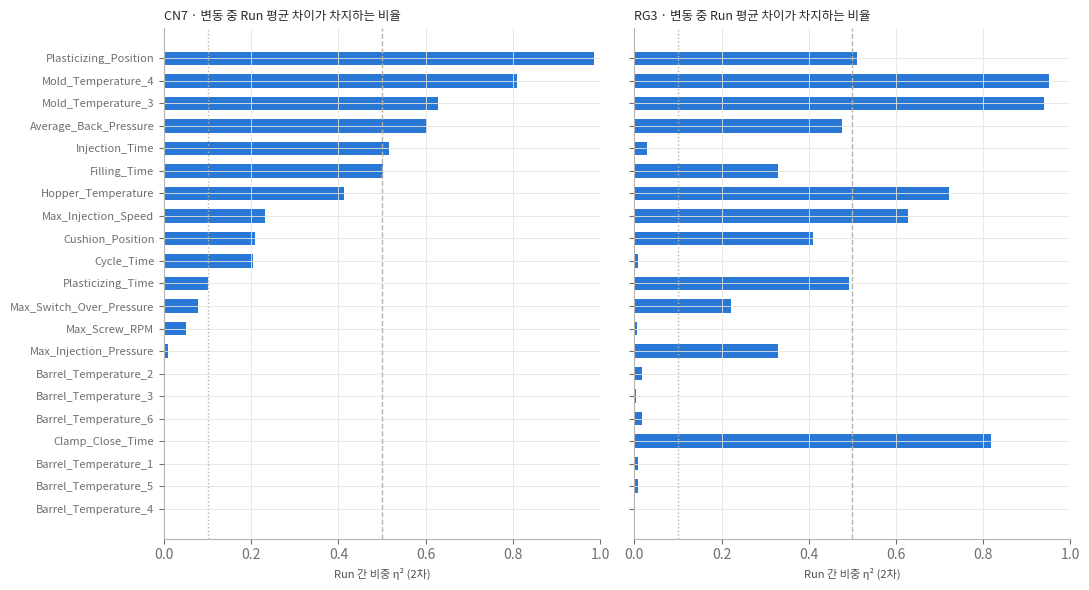

In [2]:
def eta2(df, col):
    x = df[col]; tot = ((x - x.mean()) ** 2).sum()
    if tot == 0:
        return np.nan
    bet = ((df.groupby('run_id')[col].transform('mean') - x.mean()) ** 2).sum()
    return bet / tot

rows = []
for p in PRODUCTS:
    for sp, sub in [('2차', D[p][D[p]['split'] == '2차']), ('전체', D[p])]:
        for v in VARS:
            rows.append({'제품': p.upper(), '범위': sp, '변수': v, 'η²': eta2(sub, raw(v))})
ETA = pd.DataFrame(rows).pivot_table(index='변수', columns=['제품', '범위'], values='η²')
ETA = ETA.sort_values(('CN7', '2차'), ascending=False)
display(ETA.style.format('{:.2f}', na_rep='-').background_gradient(cmap=SEQ, vmin=0, vmax=1))

fig, axes = plt.subplots(1, 2, figsize=(11, 6), sharey=True)
for ax, p in zip(axes, PRODUCTS):
    s = ETA[(p.upper(), '2차')]
    order = ETA.index[::-1]
    ax.barh(range(len(order)), s[order].values, color=SPLIT_COL['2차'], height=0.6)
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=8)
    ax.axvline(0.5, color='#b5b4ad', lw=1, ls='--'); ax.axvline(0.1, color='#b5b4ad', lw=1, ls=':')
    ax.set_xlim(0, 1); ax.set_xlabel('Run 간 비중 η² (2차)', fontsize=8)
    ax.set_title(f'{p.upper()} · 변동 중 Run 평균 차이가 차지하는 비율', loc='left', fontsize=9, color=INK)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, 'eta2_2차.png'), dpi=130, bbox_inches='tight'); plt.show()

## 3. 어떤 Run이 불량과 관계있나 — Run 평균 프로파일 vs Run 불량률

- 점 하나 = Run (파랑 2차, 주황 추가). y = Run 불량률(초기허용불량 제외 공정 불량), x = Run 평균값
- Run 수가 6개라 상관은 참고용. **불량 Run이 특정 방향으로 떨어져 있는지**를 본다

===== CN7 Run 요약 (공정변수 = Run 평균, raw 단위)


,split,샷,공정 불량률,가스,미성형,초기허용불량,Mold_Temperature_3,Hopper_Temperature,Max_Injection_Speed,Max_Switch_Over_Pressure,Max_Injection_Pressure,Plasticizing_Time,Cushion_Position,Average_Back_Pressure
run_id,,,,,,,,,,,,,,
cn7_R1,2차,188,7.4%,13,3,0,25.02,67.11,55.62,136.53,141.73,16.92,653.41,59.14
cn7_R2,2차,418,0.0%,0,0,0,22.63,68.49,56.16,136.34,141.75,17.06,653.42,59.58
cn7_R3,추가,314,0.0%,0,0,5,22.12,66.46,55.17,136.95,142.14,16.83,653.45,59.71
cn7_R4,추가,189,0.0%,0,0,0,22.85,68.29,55.42,136.59,141.87,16.92,653.43,59.43
cn7_R5,추가,407,0.0%,0,0,0,21.40,67.19,55.87,136.22,141.79,16.81,653.44,59.42
cn7_R6,추가,463,0.2%,0,1,0,21.51,65.29,55.02,136.69,142.12,16.59,653.43,59.84


===== RG3 Run 요약 (공정변수 = Run 평균, raw 단위)


,split,샷,공정 불량률,가스,미성형,초기허용불량,Mold_Temperature_3,Hopper_Temperature,Max_Injection_Speed,Max_Switch_Over_Pressure,Max_Injection_Pressure,Plasticizing_Time,Cushion_Position,Average_Back_Pressure
run_id,,,,,,,,,,,,,,
rg3_R1,2차,41,0.0%,0,0,0,21.44,65.88,128.41,116.12,142.43,13.01,654.27,60.41
rg3_R2,2차,103,4.9%,4,1,0,21.95,65.98,128.29,116.12,142.56,12.95,654.26,60.61
rg3_R3,2차,197,5.1%,6,4,0,22.73,66.44,128.29,116.04,142.56,12.93,654.26,60.66
rg3_R4,2차,74,5.4%,3,1,0,21.72,63.86,128.11,116.55,142.72,12.91,654.25,61.14
rg3_R5,2차,176,3.4%,4,2,0,23.41,65.17,128.11,116.51,142.71,12.89,654.25,61.23
rg3_R6,추가,36,19.4%,5,2,0,22.39,63.86,127.23,118.90,143.32,13.13,654.24,62.32


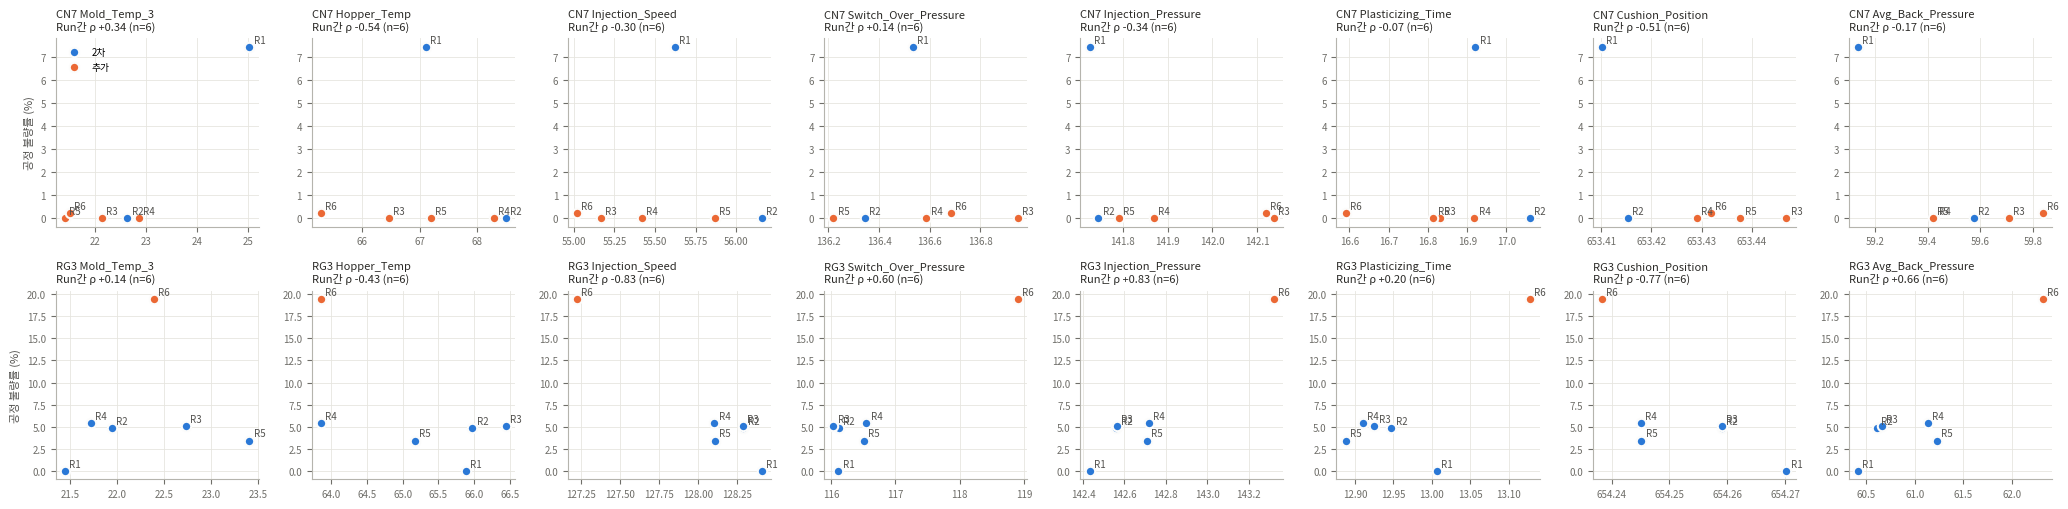

In [3]:
KEY = ['Mold_Temperature_3', 'Hopper_Temperature', 'Max_Injection_Speed', 'Max_Switch_Over_Pressure',
       'Max_Injection_Pressure', 'Plasticizing_Time', 'Cushion_Position', 'Average_Back_Pressure']

def run_table(df):
    g = df.groupby('run_id', sort=False)
    t = pd.DataFrame({'split': g['split'].first(), '샷': g.size(),
                      '공정 불량률': g['PassOrFail_process'].mean(),
                      '가스': g['Reason'].apply(lambda s: s.str.contains('가스').sum()),
                      '미성형': g['Reason'].apply(lambda s: s.str.contains('미성형').sum()),
                      '초기허용불량': g['Reason'].apply(lambda s: (s == '초기허용불량').sum())})
    for v in KEY:
        t[v] = g[raw(v)].mean()
    return t

RUN = {p: run_table(D[p]) for p in PRODUCTS}
for p in PRODUCTS:
    print(f'===== {p.upper()} Run 요약 (공정변수 = Run 평균, raw 단위)')
    display(RUN[p].style.format({'공정 불량률': '{:.1%}', **{v: '{:.2f}' for v in KEY}}))

fig, axes = plt.subplots(len(PRODUCTS), len(KEY), figsize=(2.6 * len(KEY), 5.2))
for i, p in enumerate(PRODUCTS):
    t = RUN[p]
    for j, v in enumerate(KEY):
        ax = axes[i, j]
        for sp, g in t.groupby('split'):
            ax.scatter(g[v], g['공정 불량률'] * 100, s=46, color=SPLIT_COL[sp], edgecolors='#fcfcfb', linewidths=1.5, label=sp, zorder=3)
        for r, row in t.iterrows():
            ax.annotate(r.split('_')[1], (row[v], row['공정 불량률'] * 100), fontsize=7, color='#52514e',
                        xytext=(3, 3), textcoords='offset points')
        rho = stats.spearmanr(t[v], t['공정 불량률']).statistic if t[v].nunique() > 1 else np.nan
        ax.set_title(f"{p.upper()} {v.replace('Temperature', 'Temp').replace('Max_', '').replace('Average_', 'Avg_')}\nRun간 ρ {rho:+.2f} (n={len(t)})",
                     loc='left', fontsize=8, color=INK)
        ax.tick_params(labelsize=7); ax.ticklabel_format(useOffset=False, style='plain', axis='x')
        if j == 0:
            ax.set_ylabel('공정 불량률 (%)', fontsize=8)
            if i == 0: ax.legend(fontsize=7, frameon=False)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, 'run_profile_vs_rate.png'), dpi=130, bbox_inches='tight'); plt.show()

## 4. 같은 Run 안에서 불량 샷만 튀는 변수가 있나 — Run 내 편차

- 각 샷을 **같은 Run 양품 샷의 중앙값·MAD**로 표준화한 robust z (Run 간 차이 제거)
  - 분모 하한 = max(1.4826×MAD, 0.5×표준편차, **측정 해상도**) → 값이 0.93/0.94처럼 계단형인 변수에서 기록 단위 1칸 차이로 z가 폭주하는 것 방지
- 히트맵: 불량 유형 × 변수별 **|z| 중앙값** (진할수록 불량 샷이 같은 Run 양품에서 멀리 떨어짐)
- 표: 불량이 있는 Run 안에서 불량 vs 양품 **Cliff's δ** (−1~+1, |δ| ≥ 0.33 중간, ≥ 0.47 큼)

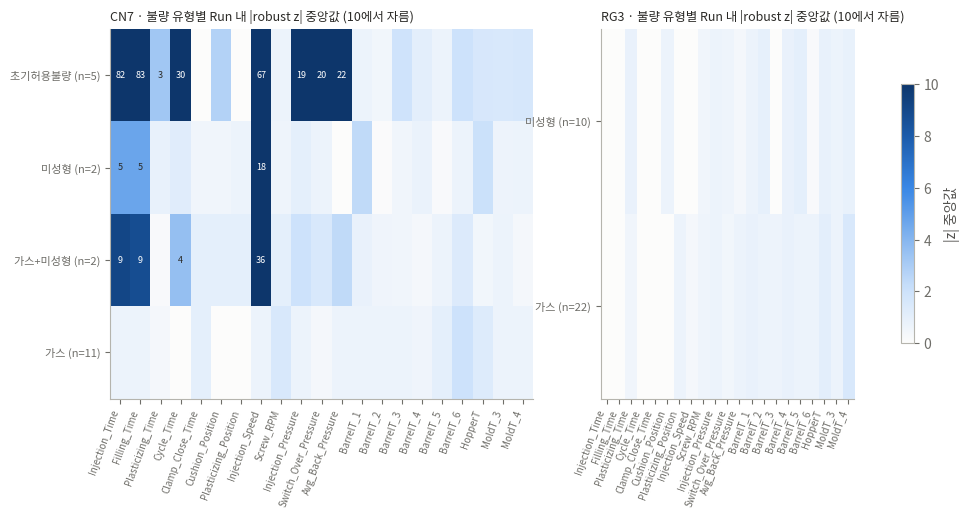

,제품,유형,불량 샷,변수,δ,|z| 중앙값
67,CN7,가스,11,Clamp_Close_Time,+0.65,1.0
81,CN7,가스,11,Hopper_Temperature,+0.36,1.3
80,CN7,가스,11,Barrel_Temperature_6,+0.35,2.0
74,CN7,가스,11,Average_Back_Pressure,+0.31,0.7
82,CN7,가스,11,Mold_Temperature_3,+0.30,0.7
42,CN7,가스+미성형,2,Injection_Time,-1.00,9.1
43,CN7,가스+미성형,2,Filling_Time,-1.00,8.8
47,CN7,가스+미성형,2,Cushion_Position,-1.00,1.0
49,CN7,가스+미성형,2,Max_Injection_Speed,+1.00,36.1
51,CN7,가스+미성형,2,Max_Injection_Pressure,-1.00,2.0


In [4]:
def resolution(x):
    u = np.sort(pd.unique(x.dropna().round(6)))
    d = np.diff(u)
    return d[d > 0].min() if (d > 0).any() else 0.0

def robust_z(df):
    Z = pd.DataFrame(index=df.index, columns=VARS, dtype=float)
    STEP = {v: resolution(df[raw(v)]) for v in VARS}      # 측정 해상도(기록 단위)
    for r, g in df.groupby('run_id'):
        ref = g[g['PassOrFail'] == 0]
        for v in VARS:
            x = ref[raw(v)]
            med = x.median()
            scale = max(1.4826 * (x - med).abs().median(), 0.5 * x.std(ddof=0), STEP[v])
            Z.loc[g.index, v] = (g[raw(v)] - med) / scale if scale > 0 else np.nan
    return Z

Z = {p: robust_z(D[p]) for p in PRODUCTS}

def cliffs(a, b):
    a, b = np.asarray(a), np.asarray(b)
    if len(a) == 0 or len(b) == 0:
        return np.nan
    return (stats.mannwhitneyu(a, b).statistic * 2) / (len(a) * len(b)) - 1

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={'width_ratios': [4, 2.4]})
PROFILE = {}
for ax, p in zip(axes, PRODUCTS):
    df, z = D[p], Z[p]
    types = [t for t in ['초기허용불량', '미성형', '가스+미성형', '가스'] if (df['Reason'] == t).any()]
    M = pd.DataFrame({f"{t} (n={int((df['Reason'] == t).sum())})": z[df['Reason'] == t].abs().median() for t in types}).T
    PROFILE[p] = M
    im = ax.imshow(np.clip(M.values.astype(float), 0, 10), cmap=SEQ, vmin=0, vmax=10, aspect='auto')
    ax.set_yticks(range(len(M))); ax.set_yticklabels(M.index, fontsize=8)
    ax.set_xticks(range(len(VARS))); ax.set_xticklabels([v.replace('_Temperature', 'T').replace('Max_', '').replace('Average_', 'Avg_') for v in VARS],
                                                        rotation=70, ha='right', fontsize=7)
    ax.grid(False)
    for a in range(M.shape[0]):
        for b in range(M.shape[1]):
            val = M.values[a, b]
            if pd.notna(val) and val >= 3:
                ax.text(b, a, f'{val:.0f}', ha='center', va='center', fontsize=6.5, color='#ffffff' if val >= 6 else INK)
    ax.set_title(f'{p.upper()} · 불량 유형별 Run 내 |robust z| 중앙값 (10에서 자름)', loc='left', fontsize=9, color=INK)
fig.colorbar(im, ax=axes, shrink=0.7, label='|z| 중앙값')
fig.savefig(os.path.join(OUT_DIR, 'within_run_z_by_type.png'), dpi=130, bbox_inches='tight'); plt.show()

rows = []
for p in PRODUCTS:
    df, z = D[p], Z[p]
    for t in ['초기허용불량', '미성형', '가스+미성형', '가스']:
        f = df['Reason'] == t
        if not f.any():
            continue
        runs = df.loc[f, 'run_id'].unique()
        n = (df['PassOrFail'] == 0) & df['run_id'].isin(runs)
        for v in VARS:
            rows.append({'제품': p.upper(), '유형': t, '불량 샷': int(f.sum()), '변수': v,
                         'δ': cliffs(z.loc[f, v].dropna(), z.loc[n, v].dropna()), '|z| 중앙값': z.loc[f, v].abs().median()})
DELTA = pd.DataFrame(rows)
TOP = (DELTA.assign(absd=DELTA['δ'].abs()).sort_values(['제품', '유형', 'absd'], ascending=[True, True, False])
       .groupby(['제품', '유형']).head(5).drop(columns='absd'))
display(TOP.style.format({'δ': '{:+.2f}', '|z| 중앙값': '{:.1f}'}))

## 5. 팀원이 본 CN7 초기허용불량·미성형 특징 — 타임라인으로 확인

- **초기허용불량 (cn7_R3)**: 짧은 정지 직후 재가동 1~5번째 샷. 사출속도가 38 → 53으로 **램프업**, 충전·사출시간 길어짐, 배압 급등
- **미성형 (cn7_R1 59~61번째)**: 연속 3샷에서 사출속도가 약 5 **급등**(55.6 → 60.8), 충전시간 짧아짐
- 같은 모양이 **양품**에서도 나오는지(오탐 후보) 함께 표시: R2 마지막 2샷(가동 종료 직전), R5 정지 직후 1샷
- 점선 세로선 = 짧은 정지 직후 샷

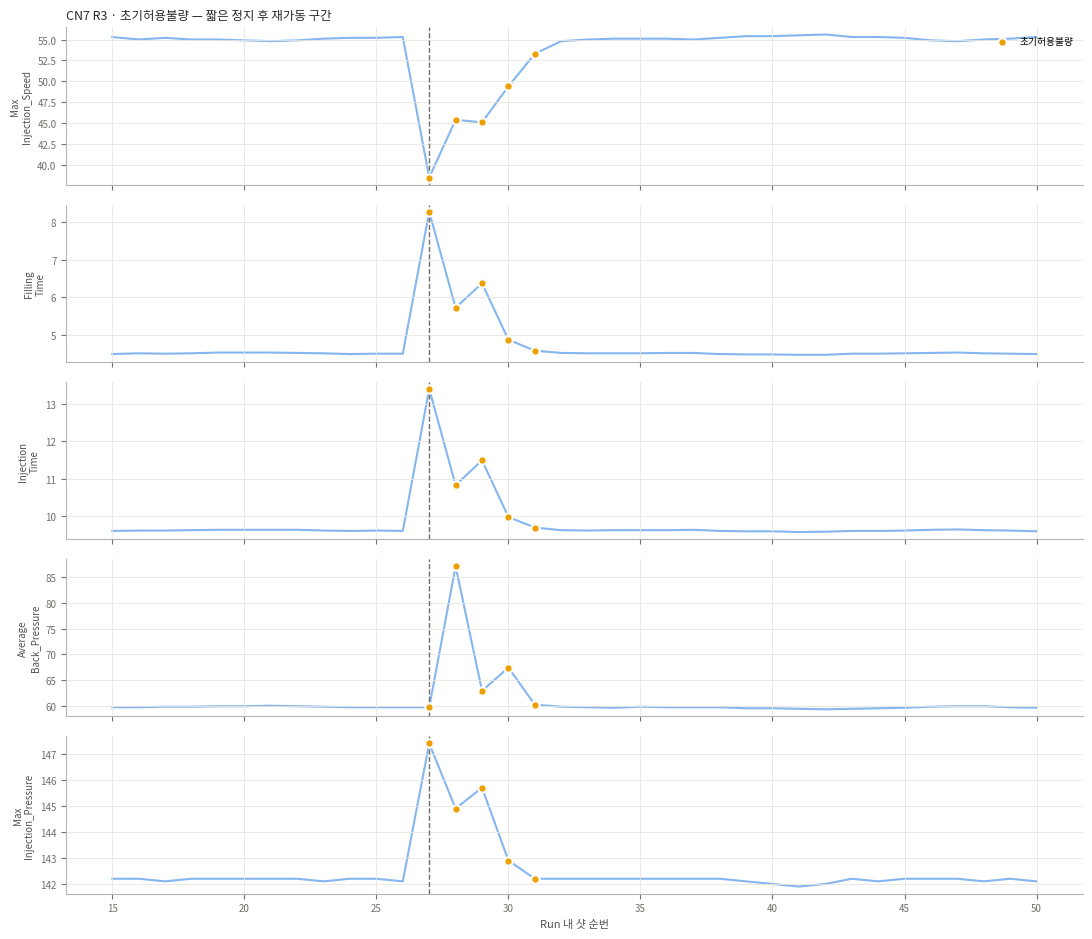

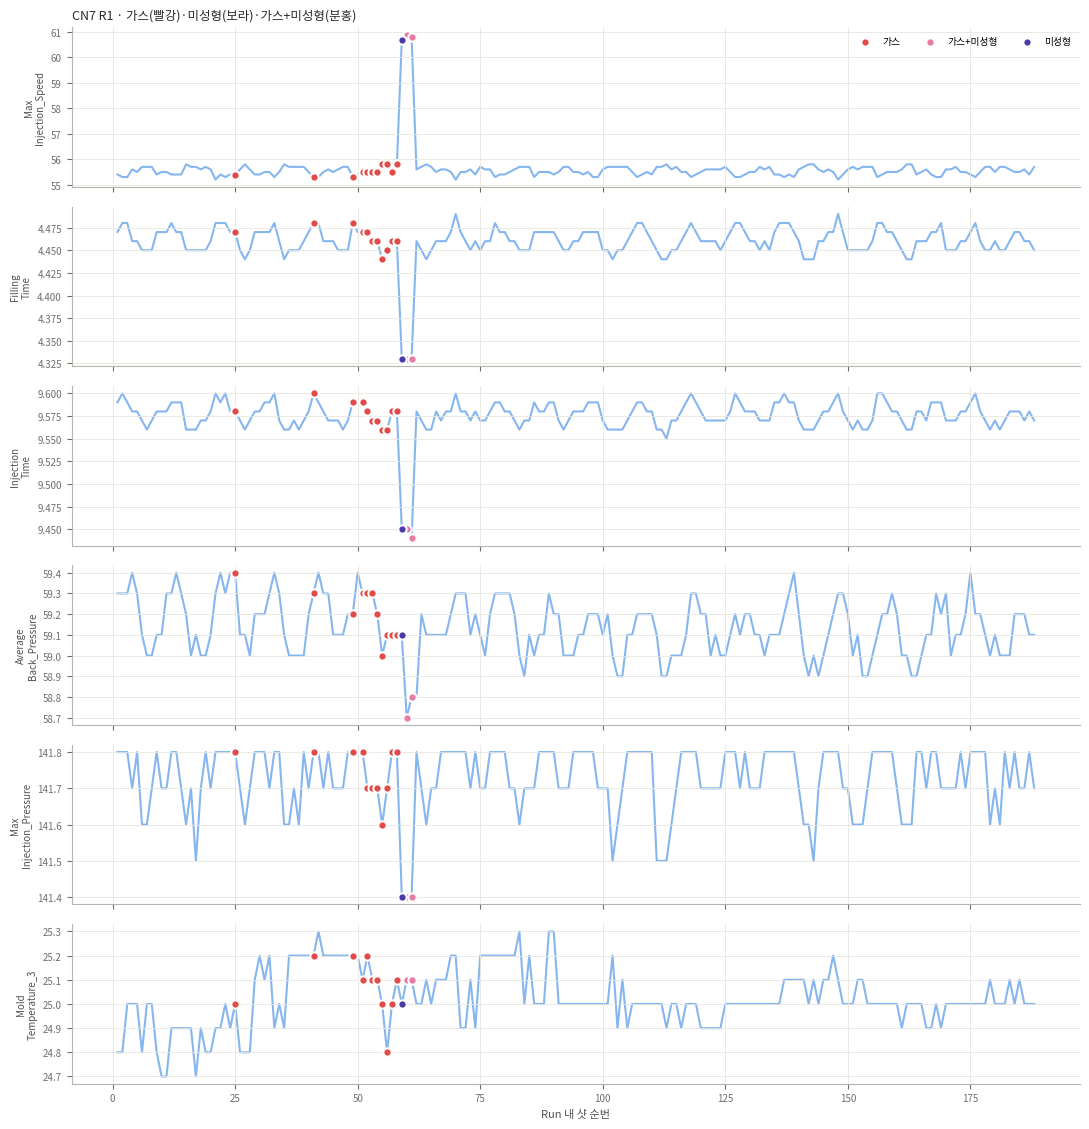

,run_id,shot_seq_in_run,shots_since_stop,after_stop,Reason,LH_fail,RH_fail,Max_Injection_Speed_raw,Filling_Time_raw,Injection_Time_raw,Average_Back_Pressure_raw
58,cn7_R1,59,59,False,미성형,1.0,1.0,60.700001,4.33,9.45,59.099998
59,cn7_R1,60,60,False,가스+미성형,1.0,1.0,60.900002,4.33,9.45,58.700001
60,cn7_R1,61,61,False,가스+미성형,1.0,1.0,60.799999,4.33,9.44,58.799999
632,cn7_R3,27,1,True,초기허용불량,1.0,1.0,38.500000,8.27,13.39,59.700001
633,cn7_R3,28,2,False,초기허용불량,1.0,1.0,45.400002,5.72,10.83,87.099998
634,cn7_R3,29,3,False,초기허용불량,1.0,1.0,45.099998,6.37,11.49,62.900002
635,cn7_R3,30,4,False,초기허용불량,1.0,1.0,49.400002,4.87,9.98,67.400002
636,cn7_R3,31,5,False,초기허용불량,1.0,1.0,53.299999,4.58,9.70,60.200001
1763,cn7_R6,248,248,False,미성형,1.0,0.0,55.000000,4.48,9.60,59.900002


In [5]:
def timeline(p, run, vars_, window=None, title=''):
    df = D[p][D[p]['run_id'] == run]
    if window:
        df = df[(df['shot_seq_in_run'] >= window[0]) & (df['shot_seq_in_run'] <= window[1])]
    fig, axes = plt.subplots(len(vars_), 1, figsize=(11, 1.9 * len(vars_)), sharex=True)
    for ax, v in zip(np.atleast_1d(axes), vars_):
        ax.plot(df['shot_seq_in_run'], df[raw(v)], color='#86b6ef', lw=1.5, zorder=1)
        for rs, g in df[df['Reason'] != '정상'].groupby('Reason'):
            ax.scatter(g['shot_seq_in_run'], g[raw(v)], s=36, color=REASON_COL[rs], edgecolors='#fcfcfb', linewidths=1.5,
                       zorder=3, label=rs)
        for s in df.loc[df['after_stop'], 'shot_seq_in_run']:
            ax.axvline(s, color='#6f6e69', lw=1, ls='--')
        ax.set_ylabel(v.replace('_', '\n', 1), fontsize=7); ax.tick_params(labelsize=7)
        ax.ticklabel_format(useOffset=False, style='plain', axis='y')
    np.atleast_1d(axes)[0].legend(fontsize=7, frameon=False, ncol=4, loc='upper right')
    np.atleast_1d(axes)[0].set_title(title, loc='left', fontsize=9, color=INK)
    np.atleast_1d(axes)[-1].set_xlabel('Run 내 샷 순번', fontsize=8)
    fig.tight_layout()
    return fig

TV = ['Max_Injection_Speed', 'Filling_Time', 'Injection_Time', 'Average_Back_Pressure', 'Max_Injection_Pressure']
f1 = timeline('cn7', 'cn7_R3', TV, (15, 50), 'CN7 R3 · 초기허용불량 — 짧은 정지 후 재가동 구간')
f1.savefig(os.path.join(OUT_DIR, 'timeline_cn7_R3_initial.png'), dpi=130, bbox_inches='tight'); plt.show()
f2 = timeline('cn7', 'cn7_R1', TV + ['Mold_Temperature_3'], (1, 188), 'CN7 R1 · 가스(빨강)·미성형(보라)·가스+미성형(분홍)')
f2.savefig(os.path.join(OUT_DIR, 'timeline_cn7_R1.png'), dpi=130, bbox_inches='tight'); plt.show()

# 유형별 불량 샷 원래 값
cols = ['run_id', 'shot_seq_in_run', 'shots_since_stop', 'after_stop', 'Reason', 'LH_fail', 'RH_fail'] + [raw(v) for v in TV[:4]]
display(D['cn7'][D['cn7']['Reason'].isin(['초기허용불량', '미성형', '가스+미성형'])][cols])

## 6. 과도구간 규칙으로 쓰면 — 탐지·오탐

| 규칙 | 정의 | 근거 |
|---|---|---|
| R-A (CN7 고정값) | 사출속도 ≥ 58 | 미성형 3샷의 속도 급등 |
| R-B (CN7 고정값) | 사출속도 ≤ 53 또는 충전시간 ≥ 4.6 | 초기허용불량 램프업 |
| R-Z (제품 공통) | 사출속도 또는 충전시간의 Run 내 robust \|z\| ≥ `Z_EVENT` | 고정값 대신 Run마다 자기 기준 |

- 탐지 = 해당 유형 불량 샷 중 규칙에 걸린 비율 / 오탐 = 규칙에 걸린 양품 샷 수
- 걸린 양품이 **재가동 직후·가동 종료 직전**이면 "불량 신호"가 아니라 "과도구간 신호"라는 뜻

In [6]:
def rules(p):
    df, z = D[p], Z[p]
    R = {'R-Z (|z|≥%d)' % Z_EVENT: (z['Max_Injection_Speed'].abs() >= Z_EVENT) | (z['Filling_Time'].abs() >= Z_EVENT)}
    if p == 'cn7':
        R = {'R-A (속도≥58)': df[raw('Max_Injection_Speed')] >= 58,
             'R-B (속도≤53 or 충전≥4.6)': (df[raw('Max_Injection_Speed')] <= 53) | (df[raw('Filling_Time')] >= 4.6), **R}
    return R

rows, hits = [], []
for p in PRODUCTS:
    df = D[p]
    last = df.groupby('run_id')['shot_seq_in_run'].transform('max') - df['shot_seq_in_run'] < 3
    for name, m in rules(p).items():
        m = m.fillna(False)
        rec = {'제품': p.upper(), '규칙': name, '걸린 샷': int(m.sum()), '오탐(양품)': int((m & (df['PassOrFail'] == 0)).sum())}
        for t in ['초기허용불량', '미성형', '가스+미성형', '가스']:
            f = df['Reason'] == t
            if f.any():
                rec[t] = f'{int((m & f).sum())}/{int(f.sum())}'
        fp = df[m & (df['PassOrFail'] == 0)]
        rec['오탐 중 재가동 5샷 이내'] = int((fp['shots_since_stop'] <= 5).sum())
        rec['오탐 중 Run 끝 3샷'] = int(last[fp.index].sum())
        rows.append(rec)
        h = df[m][['run_id', 'shot_seq_in_run', 'shots_since_stop', 'Reason', raw('Max_Injection_Speed'), raw('Filling_Time')]].copy()
        h.insert(0, '규칙', name); h.insert(0, '제품', p.upper()); hits.append(h)
RULES = pd.DataFrame(rows)
display(RULES.fillna('-'))
HITS = pd.concat(hits)
display(HITS)

,제품,규칙,걸린 샷,오탐(양품),초기허용불량,미성형,가스+미성형,가스,오탐 중 재가동 5샷 이내,오탐 중 Run 끝 3샷
0,CN7,R-A (속도≥58),5,2,0/5,1/2,2/2,0/11,0,2
1,CN7,R-B (속도≤53 or 충전≥4.6),5,1,4/5,0/2,0/2,0/11,1,0
2,CN7,R-Z (|z|≥5),14,6,5/5,1/2,2/2,0/11,3,3
3,RG3,R-Z (|z|≥5),0,0,-,0/10,-,0/22,0,0


,제품,규칙,run_id,shot_seq_in_run,shots_since_stop,Reason,Max_Injection_Speed_raw,Filling_Time_raw
58,CN7,R-A (속도≥58),cn7_R1,59,59,미성형,60.700001,4.33
59,CN7,R-A (속도≥58),cn7_R1,60,60,가스+미성형,60.900002,4.33
60,CN7,R-A (속도≥58),cn7_R1,61,61,가스+미성형,60.799999,4.33
604,CN7,R-A (속도≥58),cn7_R2,417,417,정상,58.799999,4.32
605,CN7,R-A (속도≥58),cn7_R2,418,418,정상,60.500000,4.24
632,CN7,R-B (속도≤53 or 충전≥4.6),cn7_R3,27,1,초기허용불량,38.500000,8.27
633,CN7,R-B (속도≤53 or 충전≥4.6),cn7_R3,28,2,초기허용불량,45.400002,5.72
634,CN7,R-B (속도≤53 or 충전≥4.6),cn7_R3,29,3,초기허용불량,45.099998,6.37
635,CN7,R-B (속도≤53 or 충전≥4.6),cn7_R3,30,4,초기허용불량,49.400002,4.87
1260,CN7,R-B (속도≤53 or 충전≥4.6),cn7_R5,152,1,정상,49.299999,4.82


## 7. Run 수 부족 보완 — 30샷 시간 블록 분석

Run(제품당 6개)은 비교 단위로 너무 적어서, Run을 **연속 30샷 블록**으로 쪼갠다.

- **블록 간 비중**: 블록 평균 차이가 변동에서 차지하는 비율 (Run 간 η²의 블록판)
- **블록 평균 vs 블록 불량률**: 블록 평균을 **Run 평균 대비 편차**로 바꿔(Run 효과 제거) Spearman ρ
  - Run 안에서 "변수가 평소보다 높은/낮은 30샷 구간에 불량이 몰리는가"를 본다 (회의록: 가스는 특정 시점에 몰림)
- 블록 불량률은 공정 불량(`PassOrFail_process`) 기준. 가스·미성형은 따로도 계산

In [7]:
def make_blocks(df):
    df = df.copy()
    df['block'] = df['run_id'] + '_B' + ((df['shot_seq_in_run'] - 1) // BLOCK).astype(str)
    g = df.groupby('block', sort=False)
    B = pd.DataFrame({'run_id': g['run_id'].first(), 'split': g['split'].first(), '샷': g.size(),
                      '불량률': g['PassOrFail_process'].mean(),
                      '가스율': g['Reason'].apply(lambda s: s.str.contains('가스').mean()),
                      '미성형율': g['Reason'].apply(lambda s: s.str.contains('미성형').mean())})
    for v in VARS:
        B[v] = g[raw(v)].mean()
        B[v + '_dev'] = B[v] - B.groupby('run_id')[v].transform('mean')    # Run 평균 대비 편차
    return B[B['샷'] >= BLOCK // 2]       # 너무 짧은 꼬리 블록 제외

BLK = {p: make_blocks(D[p]) for p in PRODUCTS}
rows = []
for p in PRODUCTS:
    for sp in ['2차', '전체']:
        B = BLK[p] if sp == '전체' else BLK[p][BLK[p]['split'] == '2차']
        for v in VARS:
            rec = {'제품': p.upper(), '범위': sp, '블록 수': len(B), '변수': v}
            for tgt in ['불량률', '가스율', '미성형율']:
                ok = B[v + '_dev'].nunique() > 1 and B[tgt].nunique() > 1
                rec[f'ρ({tgt})'] = stats.spearmanr(B[v + '_dev'], B[tgt]).statistic if ok else np.nan
            rows.append(rec)
BLOCK_CORR = pd.DataFrame(rows)
for p in PRODUCTS:
    t = BLOCK_CORR[(BLOCK_CORR['제품'] == p.upper()) & (BLOCK_CORR['범위'] == '2차')].copy()
    t = t.reindex(t['ρ(불량률)'].abs().sort_values(ascending=False).index).head(8)
    print(f'===== {p.upper()} 2차 · 블록 수 {int(t["블록 수"].iloc[0])} · Run 평균 대비 블록 편차 vs 블록 불량률 상위')
    display(t.style.format({c: '{:+.2f}' for c in t.columns if c.startswith('ρ')}, na_rep='-'))

===== CN7 2차 · 블록 수 20 · Run 평균 대비 블록 편차 vs 블록 불량률 상위


,제품,범위,블록 수,변수,ρ(불량률),ρ(가스율),ρ(미성형율)
4,CN7,2차,20,Clamp_Close_Time,+0.47,+0.47,+0.28
11,CN7,2차,20,Average_Back_Pressure,+0.33,+0.33,+0.18
13,CN7,2차,20,Barrel_Temperature_2,-0.29,-0.29,-0.27
16,CN7,2차,20,Barrel_Temperature_5,-0.23,-0.23,-0.31
7,CN7,2차,20,Max_Injection_Speed,+0.23,+0.23,+0.46
17,CN7,2차,20,Barrel_Temperature_6,+0.22,+0.22,+0.43
14,CN7,2차,20,Barrel_Temperature_3,+0.21,+0.21,+0.06
3,CN7,2차,20,Cycle_Time,+0.21,+0.21,+0.11


===== RG3 2차 · 블록 수 19 · Run 평균 대비 블록 편차 vs 블록 불량률 상위


,제품,범위,블록 수,변수,ρ(불량률),ρ(가스율),ρ(미성형율)
62,RG3,2차,19,Mold_Temperature_4,-0.27,-0.17,-0.26
54,RG3,2차,19,Barrel_Temperature_1,-0.26,-0.12,-0.27
47,RG3,2차,19,Cushion_Position,+0.26,+0.38,-0.13
53,RG3,2차,19,Average_Back_Pressure,-0.24,-0.32,+0.08
61,RG3,2차,19,Mold_Temperature_3,-0.22,-0.15,-0.18
60,RG3,2차,19,Hopper_Temperature,-0.20,-0.11,-0.20
52,RG3,2차,19,Max_Switch_Over_Pressure,+0.20,-0.02,+0.47
51,RG3,2차,19,Max_Injection_Pressure,-0.19,-0.31,+0.18


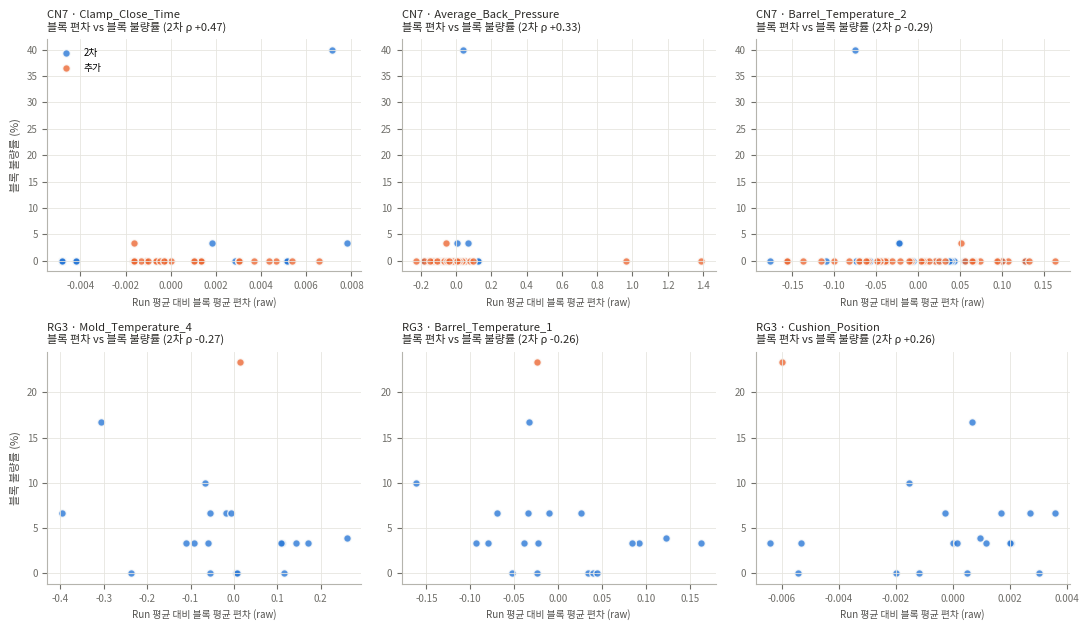

In [8]:
# 상위 변수 산점도: 블록 편차 vs 블록 불량률 (2차 + 추가 색 구분)
fig, axes = plt.subplots(len(PRODUCTS), 3, figsize=(11, 6.4))
for i, p in enumerate(PRODUCTS):
    t = BLOCK_CORR[(BLOCK_CORR['제품'] == p.upper()) & (BLOCK_CORR['범위'] == '2차')]
    top = t.reindex(t['ρ(불량률)'].abs().sort_values(ascending=False).index)['변수'].head(3).tolist()
    for j, v in enumerate(top):
        ax = axes[i, j]
        for sp, g in BLK[p].groupby('split'):
            ax.scatter(g[v + '_dev'], g['불량률'] * 100, s=30, color=SPLIT_COL[sp], alpha=0.8, edgecolors='#fcfcfb', linewidths=1, label=sp)
        r = t.set_index('변수').loc[v, 'ρ(불량률)']
        ax.set_title(f'{p.upper()} · {v}\n블록 편차 vs 블록 불량률 (2차 ρ {r:+.2f})', loc='left', fontsize=8, color=INK)
        ax.set_xlabel('Run 평균 대비 블록 평균 편차 (raw)', fontsize=7); ax.tick_params(labelsize=7)
        if j == 0:
            ax.set_ylabel('블록 불량률 (%)', fontsize=8)
            if i == 0: ax.legend(fontsize=7, frameon=False)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, 'block_dev_vs_rate.png'), dpi=130, bbox_inches='tight'); plt.show()

## 8. 저장

In [9]:
ETA.to_csv(os.path.join(OUT_DIR, 'eta2.csv'), encoding='utf-8-sig')
pd.concat({p.upper(): RUN[p] for p in PRODUCTS}).to_csv(os.path.join(OUT_DIR, 'run_profile.csv'), encoding='utf-8-sig')
DELTA.to_csv(os.path.join(OUT_DIR, 'within_run_delta.csv'), index=False, encoding='utf-8-sig')
RULES.to_csv(os.path.join(OUT_DIR, 'rules.csv'), index=False, encoding='utf-8-sig')
HITS.to_csv(os.path.join(OUT_DIR, 'rule_hits.csv'), index=False, encoding='utf-8-sig')
BLOCK_CORR.to_csv(os.path.join(OUT_DIR, 'block_corr.csv'), index=False, encoding='utf-8-sig')
print('저장 위치:', os.path.abspath(OUT_DIR))

저장 위치: /tmp/claude-0/-home-claude/b6af321b-f66e-5a8f-868b-d67d3934417c/scratchpad/root/KAMP-IMM/notebooks/outputs/run


## 해석 가이드

1. **η²가 높은 변수(금형·호퍼 온도 등)** → Run 성격. 불량 Run이 이 축에서 떨어져 있으면 "Run 전체 특성형" 불량 (CN7 가스 후보)
2. **Run 내 z가 큰 유형** → 샷 단위로 튀는 "이벤트형" 불량 (CN7 초기허용불량·미성형). 단, 6장에서 **같은 모양의 양품**(재가동 직후·가동 종료 직전)이 있으면 불량 신호가 아니라 과도구간 신호 → 모델에는 `shots_since_stop`, Run 내 z 같은 **과도구간 파생변수**로 반영
3. **둘 다 약한 유형** (RG3 가스·미성형) → 공정변수로 설명이 어려움. RG3 불량은 전부 RH 캐비티(2차) → 금형·캐비티 요인 가능성, 보고서 3장 "실패 조건"으로
4. **블록 분석**은 Run 내 시간 구간 효과를 보는 것. 블록 편차와 불량률 상관이 있으면 "Run 안에서도 특정 구간에 몰림"(가설 C3)
5. **주의**: CN7 R1의 `Clamp_Close_Time`(불량 구간 7.13초 → 79번째 샷부터 7.12초)처럼 **시간 구간과 겹친 가짜 신호**가 있음. 블록·타임라인으로 시간 교란인지 꼭 확인